In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import shap
import os

from tensorflow.keras.models import load_model

In [2]:
MODEL_PATH = "../Saved_Models/best_model_finetuned.keras"

model = load_model(MODEL_PATH)

print("Model učitan.")

Model učitan.


In [3]:
class_names = [
    "Mild_DR",
    "Moderate_DR",
    "No_DR",
    "Proliferate_DR",
    "Severe_DR"
]

IMG_SIZE = (224,224)

In [4]:
def load_image(img_path):

    img = tf.keras.utils.load_img(
        img_path,
        target_size=IMG_SIZE
    )

    img_array = tf.keras.utils.img_to_array(img)

    return img_array

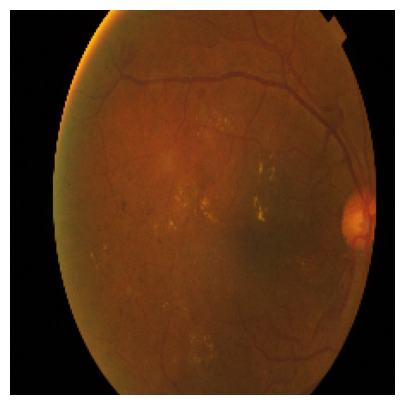

In [5]:
IMAGE_PATH = (
    "../Dataset/"
    "Moderate_DR/"
    "000c1434d8d7.png"
)

img_array = load_image(IMAGE_PATH)

plt.figure(figsize=(5,5))
plt.imshow(img_array.astype(np.uint8))
plt.axis("off")
plt.show()

In [6]:
prediction = model.predict(
    np.expand_dims(img_array, axis=0),
    verbose=0
)

predicted_index = np.argmax(prediction[0])

print("Predikcija:", class_names[predicted_index])
print("Pouzdanost:", prediction[0][predicted_index])

Predikcija: Moderate_DR
Pouzdanost: 0.46577796


In [7]:
def shap_predict(images):
    images = np.asarray(images, dtype=np.float32)

    return model.predict(
        images,
        verbose=0
    )

In [8]:
image_masker = shap.maskers.Image(
    "blur(16,16)",
    shape=(224, 224, 3)
)

partition_explainer = shap.Explainer(
    shap_predict,
    image_masker,
    algorithm="partition",
    output_names=class_names,
    seed=42
)

print("SHAP PartitionExplainer je kreiran.")

SHAP PartitionExplainer je kreiran.


In [12]:
input_image = np.expand_dims(
    img_array.astype(np.float32),
    axis=0
)

predicted_index = int(
    np.argmax(prediction[0])
)

predicted_class = class_names[predicted_index]
confidence = float(
    prediction[0][predicted_index]
)

partition_shap_values = partition_explainer(
    input_image,
    max_evals=500,
    batch_size=50,
    outputs=[predicted_index]
)

# SHAP vrijednosti ostaju nepromijenjene.
# Normalizira se samo slika koja se prikazuje.
partition_shap_values.data = (
    partition_shap_values.data.astype(np.float32) / 255.0
)



  0%|          | 0/498 [00:00<?, ?it/s]

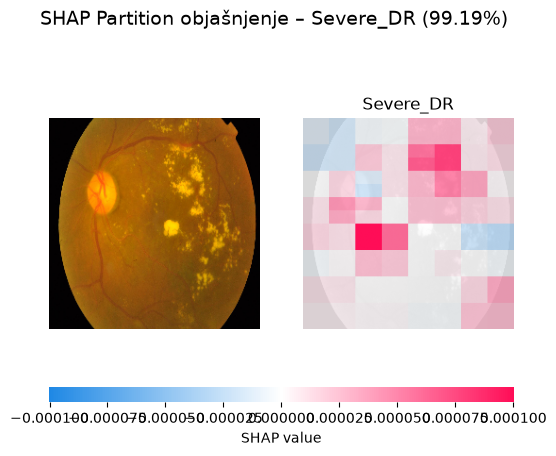

In [13]:
shap.plots.image(
    partition_shap_values,
    show=False
)

plt.suptitle(
    f"SHAP Partition objašnjenje – "
    f"{predicted_class} ({confidence:.2%})",
    fontsize=14
)

plt.show()

In [19]:
import pandas as pd

OUTPUT_DIR = "../Results/SHAP/all_classes"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TEST_PATH = "../Dataset/"

selected_images = {
    "Mild_DR": "0024cdab0c1e.png",
    "Moderate_DR": "000c1434d8d7.png",
    "No_DR": "002c21358ce6.png",
    "Proliferate_DR": "001639a390f0.png",
    "Severe_DR": "0104b032c141.png"
}

results = []

for true_class, filename in selected_images.items():

    image_path = os.path.join(
        TEST_PATH,
        true_class,
        filename
    )

    img_array = load_image(image_path)

    input_image = np.expand_dims(
        img_array.astype(np.float32),
        axis=0
    )

    prediction = model.predict(
        input_image,
        verbose=0
    )

    predicted_index = int(np.argmax(prediction[0]))
    predicted_class = class_names[predicted_index]
    confidence = float(prediction[0][predicted_index])

    explanation = partition_explainer(
        input_image,
        max_evals=500,
        batch_size=50,
        outputs=[predicted_index]
    )

    # Normalizacija samo slike za prikaz
    explanation.data = (
        explanation.data.astype(np.float32) / 255.0
    )

    shap.plots.image(
        explanation,
        show=False
    )

    fig = plt.gcf()

    fig.suptitle(
        f"{true_class} → {predicted_class}\n"
        f"Pouzdanost: {confidence:.2%}",
        fontsize=13
    )

    output_path = os.path.join(
        OUTPUT_DIR,
        f"{true_class}_pred_{predicted_class}.png"
    )

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

    results.append({
        "stvarna_klasa": true_class,
        "predvidena_klasa": predicted_class,
        "pouzdanost": confidence,
        "tocna_predikcija": true_class == predicted_class,
        "slika": filename
    })

    print(
        f"{true_class} → {predicted_class} "
        f"({confidence:.2%})"
    )

print("Broj spremljenih rezultata:", len(results))

  0%|          | 0/498 [00:00<?, ?it/s]

Mild_DR → Mild_DR (82.75%)


  0%|          | 0/498 [00:00<?, ?it/s]

Moderate_DR → Moderate_DR (46.58%)


  0%|          | 0/498 [00:00<?, ?it/s]

No_DR → No_DR (94.32%)


  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:10, 10.12s/it]               


Proliferate_DR → Proliferate_DR (42.79%)


  0%|          | 0/498 [00:00<?, ?it/s]

Severe_DR → Severe_DR (99.19%)
Broj spremljenih rezultata: 5


In [20]:
results_df = pd.DataFrame(results)
results_df

,stvarna_klasa,predvidena_klasa,pouzdanost,tocna_predikcija,slika
0,Mild_DR,Mild_DR,0.827542,True,0024cdab0c1e.png
1,Moderate_DR,Moderate_DR,0.465778,True,000c1434d8d7.png
2,No_DR,No_DR,0.943162,True,002c21358ce6.png
3,Proliferate_DR,Proliferate_DR,0.427932,True,001639a390f0.png
4,Severe_DR,Severe_DR,0.991850,True,0104b032c141.png


In [21]:
csv_path = os.path.join(
    OUTPUT_DIR,
    "shap_results.csv"
)

results_df.to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

print("CSV spremljen u:", csv_path)

CSV spremljen u: ../Results/SHAP/all_classes\shap_results.csv
